In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import cafein.sampledata.helsinki as helsinki
from cafein import TransportNetwork

# The artifact saved in "Building a network".
network = TransportNetwork.load("networks/helsinki-region.cafein")
departure = "2026-09-08 08:30"
origin = (60.16891, 24.93300)       # Kamppi: latitude, longitude
destination = (60.18700, 24.97800)  # Kalasatama


def arrival_time(candidate):
    return candidate["arrival_s"]

In [2]:
journeys = network.route_between_coordinates(
    origin,
    destination,
    departure,
)
routing_added_emissions = "emissions" in journeys[0]

network.annotate_emissions(journeys)
journey = min(journeys, key=arrival_time)

routing_added_emissions, journey["emissions"]

(False, 102.275)

In [3]:
leg_rows = []

for leg in journey["legs"]:
    service = leg.get("route_short_name")

    if service is None:
        service = leg.get("mode") or "walk"

    leg_rows.append(
        {
            "leg_type": leg["type"],
            "service": service,
            "distance_m": leg["distance_m"],
            "distance_provenance": leg.get("distance_provenance"),
            "emissions": leg["emissions"],
        }
    )

leg_emissions = pd.DataFrame(leg_rows)
leg_emissions

,leg_type,service,distance_m,distance_provenance,emissions
0,access,walk,195.722477,None,0.000
1,transit,M1,4091.000000,shape_dist,102.275
2,egress,walk,341.195488,None,0.000


In [4]:
from cafein.emissions import default_factors

defaults = default_factors()
component_columns = [
    "vehicle",
    "fuel",
    "infrastructure",
    "operations",
]
defaults_with_totals = defaults.copy()
defaults_with_totals["total"] = (
    defaults_with_totals[component_columns].sum(axis="columns")
)

display_columns = [
    "route_type",
    "vehicle",
    "fuel",
    "infrastructure",
    "operations",
    "total",
]
defaults_with_totals[display_columns]

,route_type,vehicle,fuel,infrastructure,operations,total
0,3,8.0,72.0,4.0,8.0,92.0
1,0,2.0,12.0,11.0,0.0,25.0
2,1,2.0,12.0,11.0,0.0,25.0
3,2,2.0,12.0,11.0,0.0,25.0


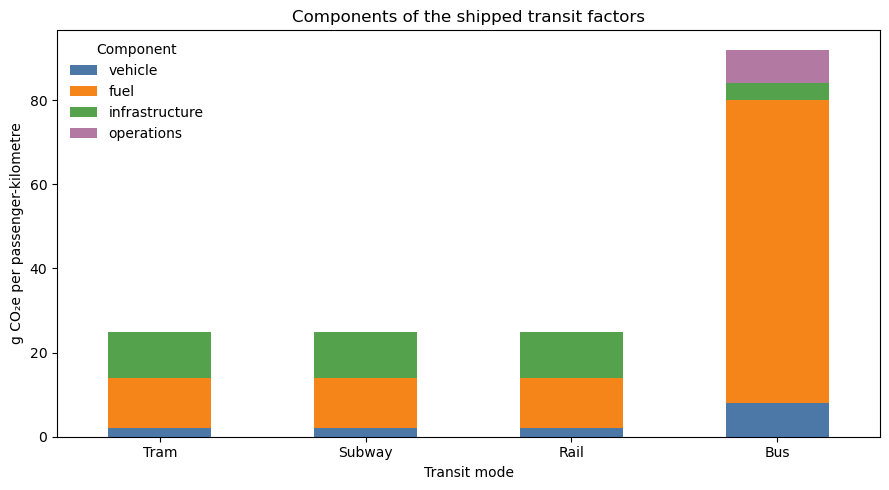

In [5]:
route_type_names = {
    0: "Tram",
    1: "Subway",
    2: "Rail",
    3: "Bus",
}

transit_components = defaults.set_index("route_type")[
    component_columns
].copy()
transit_components = transit_components.rename(index=route_type_names)
transit_components = transit_components.loc[
    ["Tram", "Subway", "Rail", "Bus"]
]

component_colours = [
    "#4C78A8",
    "#F58518",
    "#54A24B",
    "#B279A2",
]

figure, axis = plt.subplots(figsize=(9, 5))
transit_components.plot(
    ax=axis,
    kind="bar",
    stacked=True,
    color=component_colours,
)
axis.set_xlabel("Transit mode")
axis.set_ylabel("g CO₂e per passenger-kilometre")
axis.set_title("Components of the shipped transit factors")
axis.tick_params(axis="x", rotation=0)
axis.legend(title="Component", frameon=False)
figure.tight_layout()

In [6]:
from cafein.emissions import vehicle_class_factors

bus_destination = (60.1873, 24.9192)  # Töölö
electric_bus = vehicle_class_factors().loc["bus-BEV"].to_dict()
electric_bus["route_type"] = 3
custom_factors = pd.DataFrame([electric_bus])

scenario_settings = [
    ("shipped bus default", None),
    ("illustrative electric fleet", custom_factors),
]
scenario_rows = []

for label, factors in scenario_settings:
    options = network.route_between_coordinates(
        origin,
        bus_destination,
        departure,
    )
    network.annotate_emissions(options, factors=factors)
    fastest = min(options, key=arrival_time)
    scenario_rows.append(
        {"scenario": label, "emissions": fastest["emissions"]}
    )

scenario_comparison = pd.DataFrame(scenario_rows)
scenario_comparison

,scenario,emissions
0,shipped bus default,188.784
1,illustrative electric fleet,59.508


In [7]:
from cafein.emissions import street_factor

car_settings = [
    ("ICE", 1),
    ("BEV", 1),
    ("BEV", 2),
]
car_rows = []

for vehicle_class, occupancy in car_settings:
    factor_per_vehicle = street_factor(
        "car",
        vehicle_class=vehicle_class,
    )
    factor_per_person = factor_per_vehicle / occupancy

    car_rows.append(
        {
            "vehicle_class": vehicle_class,
            "occupancy": occupancy,
            "g_per_person_km": factor_per_person,
        }
    )

car_scenarios = pd.DataFrame(car_rows)
car_scenarios

,vehicle_class,occupancy,g_per_person_km
0,ICE,1,162.0
1,BEV,1,70.0
2,BEV,2,35.0


In [8]:
from cafein.emissions import street_factor_with_basis

factor, basis = street_factor_with_basis(
    "car",
    vehicle_class="BEV",
)